In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report


In [4]:

columns = [
    'id', 'diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
    'smoothness_mean', 'compactness_mean', 'concavity_mean',
    'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se',
    'smoothness_se', 'compactness_se', 'concavity_se',
    'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
    'smoothness_worst', 'compactness_worst', 'concavity_worst',
    'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]


In [5]:
from google.colab import files
uploaded = files.upload()

Saving BreastCancer.csv to BreastCancer.csv


In [6]:
data = pd.read_csv("BreastCancer.csv", header=None, names=columns)

In [7]:
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [8]:
data.shape

(569, 32)

In [9]:
data = data.drop(columns=['id'])
data = data.drop_duplicates()


In [10]:
data['diagnosis'] = data['diagnosis'].astype(str).str.strip().map({'B': 0,'M': 1})

In [11]:
data = data.dropna(subset=['diagnosis'])

In [12]:

features = data.drop(columns=['diagnosis'])
labels = data['diagnosis'].astype(int)

features = features.fillna(features.median())


In [13]:
features.isnull().sum()

,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave_points_mean,0
symmetry_mean,0
fractal_dimension_mean,0


In [14]:
print("Features:", features.shape)
print("Target:", labels.shape)

Features: (569, 30)
Target: (569,)


In [15]:
features_train, features_test, labels_train, labels_test = train_test_split(features, labels, test_size=0.2, random_state=42,)




In [16]:
features_test.shape
features_train.shape

(455, 30)

In [17]:
standardizer = StandardScaler()

features_train_scaled = standardizer.fit_transform(features_train)
features_test_scaled = standardizer.transform(features_test)


In [18]:
svm_model = SVC()
svm_model.fit(features_train_scaled, labels_train)

SVC()

In [19]:
svm_predictions = svm_model.predict(features_test_scaled)

In [31]:
print("SVM Before Tuning")
print("Accuracy:", accuracy_score(labels_test, svm_predictions))
print("Precision:", precision_score(labels_test, svm_predictions))
print("Recall:", recall_score(labels_test, svm_predictions))
print("F1 Score:", f1_score(labels_test, svm_predictions))

SVM Before Tuning
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1 Score: 0.9761904761904762


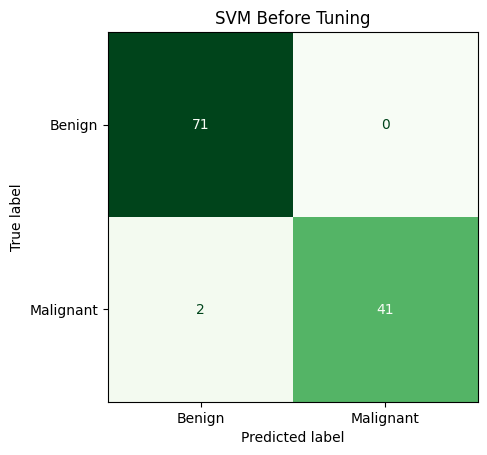

In [21]:
confusion_matrix_values = confusion_matrix(labels_test, svm_predictions)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_values,display_labels=['Benign', 'Malignant']).plot(cmap='Greens', colorbar=False)

plt.title("SVM Before Tuning")
plt.show()

In [22]:
svm_cv_scores = cross_val_score(SVC(),features_train_scaled,labels_train,cv=5,scoring='f1')

svm_cv_scores
svm_cv_scores.mean()


np.float64(0.9666922739244951)

In [23]:
svm_parameters = {'C': [0.1, 1, 10],'kernel': ['linear', 'rbf'],'gamma': ['scale', 0.01, 0.1]}

svm_search = GridSearchCV(SVC(),svm_parameters,cv=5,scoring='f1',n_jobs=-1)



In [24]:
svm_search.fit(features_train_scaled, labels_train)

GridSearchCV(cv=5, estimator=SVC(), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1],
                         'kernel': ['linear', 'rbf']},
             scoring='f1')

In [25]:
print("Best SVM Parameters:", svm_search.best_params_)
print("Best CV F1 Score:", svm_search.best_score_)

Best SVM Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV F1 Score: 0.9666922739244951


In [26]:
tuned_svm_model = svm_search.best_estimator_

In [27]:
svm_tuned_predictions = tuned_svm_model.predict(features_test_scaled)

In [30]:
print("SVM After Tuning")
print("Accuracy:", accuracy_score(labels_test, svm_tuned_predictions))
print("Precision:", precision_score(labels_test, svm_tuned_predictions))
print("Recall:", recall_score(labels_test, svm_tuned_predictions))
print("F1 Score:", f1_score(labels_test, svm_tuned_predictions))

SVM After Tuning
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1 Score: 0.9761904761904762


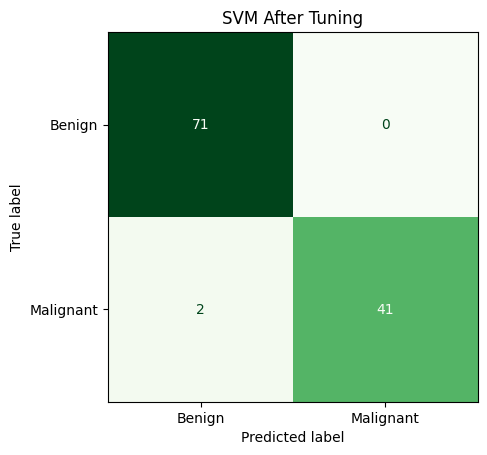

In [32]:
confusion_matrix_values = confusion_matrix(labels_test, svm_tuned_predictions)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_values,display_labels=['Benign', 'Malignant']).plot(cmap='Greens', colorbar=False)

plt.title("SVM After Tuning")
plt.show()

In [33]:
rf_model = RandomForestClassifier(random_state=42)

In [34]:
rf_model.fit(features_train, labels_train)

RandomForestClassifier(random_state=42)

In [35]:

rf_predictions = rf_model.predict(features_test)

In [36]:

print("Random Forest Before Tuning")
print("Accuracy:", accuracy_score(labels_test, rf_predictions))
print("Precision:", precision_score(labels_test, rf_predictions))
print("Recall:", recall_score(labels_test, rf_predictions))
print("F1 Score:", f1_score(labels_test, rf_predictions))

Random Forest Before Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


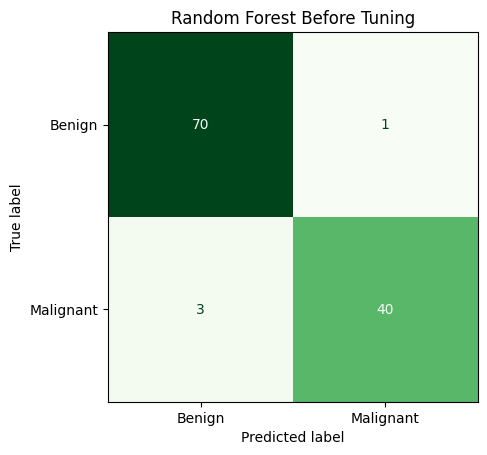

In [37]:

confusion_matrix_values = confusion_matrix(labels_test, rf_predictions)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_values,display_labels=['Benign', 'Malignant']).plot(cmap='Greens', colorbar=False)

plt.title("Random Forest Before Tuning")
plt.show()

In [38]:

rf_cv_scores = cross_val_score(RandomForestClassifier(random_state=42),features_train,labels_train,cv=5,scoring='f1')

print("Random Forest CV Scores:", rf_cv_scores)
print("Mean CV F1 Score:", rf_cv_scores.mean())


Random Forest CV Scores: [0.95238095 0.92307692 0.97142857 0.94117647 0.90909091]
Mean CV F1 Score: 0.9394307653131182


In [39]:

rf_parameters = {'n_estimators': [100, 200],'max_depth': [None, 5, 10],'min_samples_split': [2, 5]}

rf_search = GridSearchCV(RandomForestClassifier(random_state=42),rf_parameters,cv=5, scoring='f1',n_jobs=-1)


In [40]:

rf_search.fit(features_train, labels_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='f1')

In [41]:

print("Best Random Forest Parameters:", rf_search.best_params_)
print("Best CV F1 Score:", rf_search.best_score_)


Best Random Forest Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1 Score: 0.9487651808975338


In [42]:
tuned_rf_model = rf_search.best_estimator_

In [43]:
rf_tuned_predictions = tuned_rf_model.predict(features_test)


In [44]:
print("Random Forest After Tuning")
print("Accuracy:", accuracy_score(labels_test, rf_tuned_predictions))
print("Precision:", precision_score(labels_test, rf_tuned_predictions))
print("Recall:", recall_score(labels_test, rf_tuned_predictions))
print("F1 Score:", f1_score(labels_test, rf_tuned_predictions))

Random Forest After Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


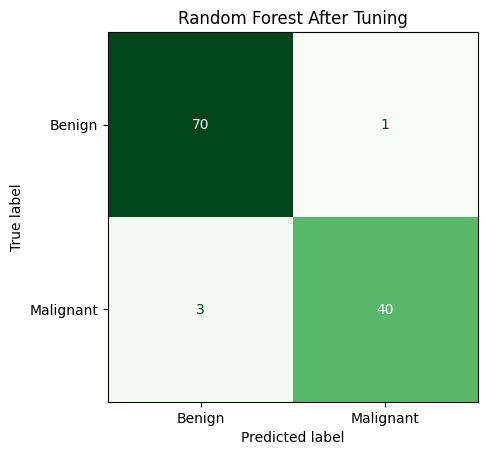

In [45]:

confusion_matrix_values = confusion_matrix(labels_test, rf_tuned_predictions)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_values,display_labels=['Benign', 'Malignant']).plot(cmap='Greens', colorbar=False)

plt.title("Random Forest After Tuning")
plt.show()

In [46]:
ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(features_train, labels_train)

AdaBoostClassifier(random_state=42)

In [47]:

ada_predictions = ada_model.predict(features_test)

In [48]:
print("AdaBoost Before Tuning")
print("Accuracy:", accuracy_score(labels_test, ada_predictions))
print("Precision:", precision_score(labels_test, ada_predictions))
print("Recall:", recall_score(labels_test, ada_predictions))
print("F1 Score:", f1_score(labels_test, ada_predictions))

AdaBoost Before Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


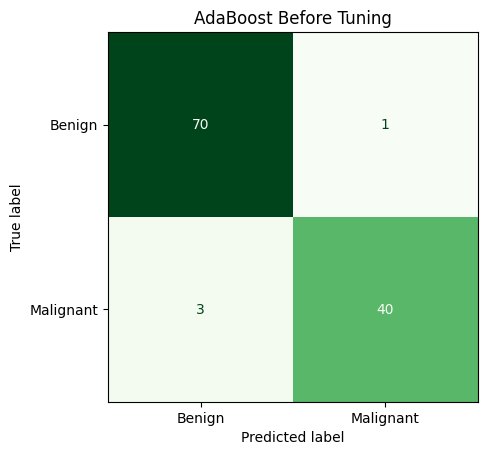

In [49]:
confusion_matrix_values = confusion_matrix(labels_test, ada_predictions)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_values,display_labels=['Benign', 'Malignant']).plot(cmap='Greens', colorbar=False)

plt.title("AdaBoost Before Tuning")
plt.show()

In [50]:
ada_cv_scores = cross_val_score(AdaBoostClassifier(random_state=42),features_train,labels_train,cv=5,scoring='f1')


In [51]:
print("AdaBoost CV Scores:", ada_cv_scores)
print("Mean CV F1 Score:", ada_cv_scores.mean())

AdaBoost CV Scores: [0.97058824 0.96969697 1.         0.96969697 0.95384615]
Mean CV F1 Score: 0.9727656657068422


In [52]:

ada_parameters = {'n_estimators': [50, 100, 200],'learning_rate': [0.1, 0.5, 1.0],'estimator': [DecisionTreeClassifier(max_depth=1, random_state=42),
        DecisionTreeClassifier(max_depth=2, random_state=42)]}

ada_search = GridSearchCV( AdaBoostClassifier(random_state=42),ada_parameters,cv=5,scoring='f1',n_jobs=-1)

In [53]:
ada_search.fit(features_train, labels_train)

GridSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=42), n_jobs=-1,
             param_grid={'estimator': [DecisionTreeClassifier(max_depth=1,
                                                              random_state=42),
                                       DecisionTreeClassifier(max_depth=2,
                                                              random_state=42)],
                         'learning_rate': [0.1, 0.5, 1.0],
                         'n_estimators': [50, 100, 200]},
             scoring='f1')

In [54]:
print("Best AdaBoost Parameters:", ada_search.best_params_)
print("Best CV F1 Score:", ada_search.best_score_)

Best AdaBoost Parameters: {'estimator': DecisionTreeClassifier(max_depth=1, random_state=42), 'learning_rate': 1.0, 'n_estimators': 50}
Best CV F1 Score: 0.9727656657068422


In [55]:
tuned_ada_model = ada_search.best_estimator_

In [56]:
ada_tuned_predictions = tuned_ada_model.predict(features_test)

In [57]:
print("AdaBoost After Tuning")
print("Accuracy:", accuracy_score(labels_test, ada_tuned_predictions))
print("Precision:", precision_score(labels_test, ada_tuned_predictions))
print("Recall:", recall_score(labels_test, ada_tuned_predictions))
print("F1 Score:", f1_score(labels_test, ada_tuned_predictions))

AdaBoost After Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


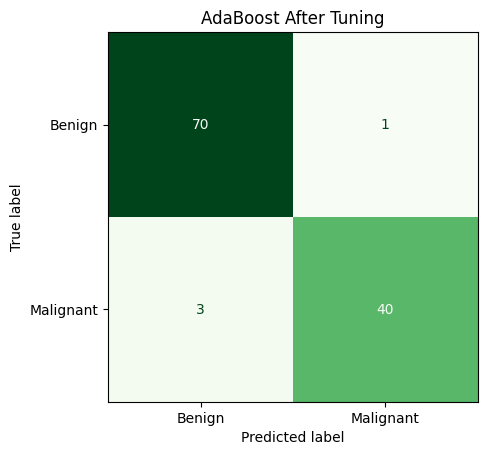

In [58]:

confusion_matrix_values = confusion_matrix(labels_test, ada_tuned_predictions)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_values,display_labels=['Benign', 'Malignant']).plot(cmap='Greens', colorbar=False)

plt.title("AdaBoost After Tuning")
plt.show()

In [59]:

model_comparison = pd.DataFrame({'Model': ['SVM', 'SVM Tuned','Random Forest', 'Random Forest Tuned','AdaBoost', 'AdaBoost Tuned'],

    'Accuracy': [
        accuracy_score(labels_test, svm_predictions),
        accuracy_score(labels_test, svm_tuned_predictions),
        accuracy_score(labels_test, rf_predictions),
        accuracy_score(labels_test, rf_tuned_predictions),
        accuracy_score(labels_test, ada_predictions),
        accuracy_score(labels_test, ada_tuned_predictions)
    ],

    'Precision': [
        precision_score(labels_test, svm_predictions),
        precision_score(labels_test, svm_tuned_predictions),
        precision_score(labels_test, rf_predictions),
        precision_score(labels_test, rf_tuned_predictions),
        precision_score(labels_test, ada_predictions),
        precision_score(labels_test, ada_tuned_predictions)
    ],

    'Recall': [
        recall_score(labels_test, svm_predictions),
        recall_score(labels_test, svm_tuned_predictions),
        recall_score(labels_test, rf_predictions),
        recall_score(labels_test, rf_tuned_predictions),
        recall_score(labels_test, ada_predictions),
        recall_score(labels_test, ada_tuned_predictions)
    ],

    'F1 Score': [
        f1_score(labels_test, svm_predictions),
        f1_score(labels_test, svm_tuned_predictions),
        f1_score(labels_test, rf_predictions),
        f1_score(labels_test, rf_tuned_predictions),
        f1_score(labels_test, ada_predictions),
        f1_score(labels_test, ada_tuned_predictions)
    ]
})

print(model_comparison.round(4))


                 Model  Accuracy  Precision  Recall  F1 Score
0                  SVM    0.9825     1.0000  0.9535    0.9762
1            SVM Tuned    0.9825     1.0000  0.9535    0.9762
2        Random Forest    0.9649     0.9756  0.9302    0.9524
3  Random Forest Tuned    0.9649     0.9756  0.9302    0.9524
4             AdaBoost    0.9649     0.9756  0.9302    0.9524
5       AdaBoost Tuned    0.9649     0.9756  0.9302    0.9524


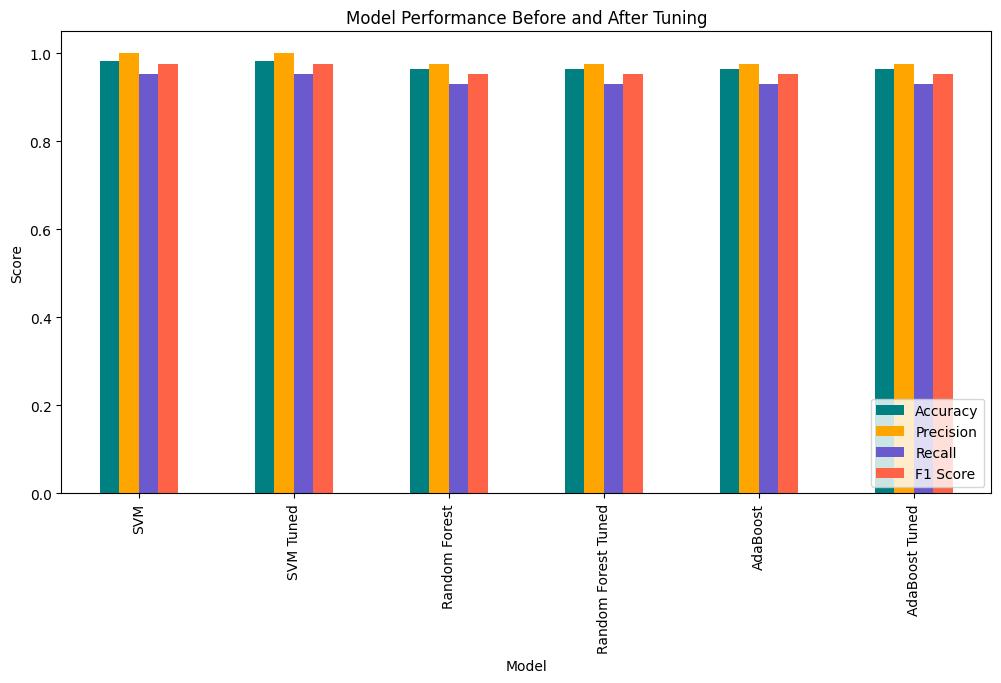

In [60]:
model_comparison.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(kind='bar', figsize=(12, 6), color=['teal', 'orange', 'slateblue', 'tomato'])

plt.title('Model Performance Before and After Tuning')
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.show()
